# Praktikum Komputasi Numerik
## Modul 5: Interpolasi Polinom (Lagrange, Newton, dan Fenomena Runge)

|  |  |
|---|---|
| Nama | Fathin Yassarahman |
| NIM | 241524041 |
| Kelas | 5B |
| Program Studi | D-4 Teknik Informatika |
| Jurusan | Teknik Komputer dan Informatika, Politeknik Negeri Bandung |
| Tanggal | 3 November 2026 |

isi notebook: Task I sampai Task IV, jawaban Tugas Praktikum (III.8), dan Soal Latihan HOTS gaya ICPC (III.9).

data uji utama adalah tabel ln x empat angka bena pada x = 1, 2, 3, 4 dengan target ln 2.5 = 0.916291. fungsi uji kedua adalah fungsi Runge f(x) = 1/(1 + 25x^2) pada [-1, 1].

---
# Task 0: Setup Environment

memeriksa python, numpy, dan matplotlib sebelum masuk materi. semua rumus interpolasi ditulis sendiri, sedangkan `math.log` dan `math.sin` hanya dipakai sebagai nilai eksak pembanding

In [1]:
print("Hello, Modul 5!")

import sys
print("Python version:", sys.version.split()[0])

import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
print("NumPy version     :", np.__version__)
print("Matplotlib version:", matplotlib.__version__)

Hello, Modul 5!
Python version: 3.13.18


NumPy version     : 2.5.3
Matplotlib version: 3.11.2


---
# Task I: Interpolasi Linier dan Kuadratik

menaksir ln 2.5 dari tabel ln x dengan garis lurus dua titik, lalu dengan parabola tiga titik. ada dua trio yang memuat x = 2.5, dan keduanya dibandingkan

In [2]:
# I.1 tabel ln x empat angka bena dan interpolasi linier antara x = 2 dan x = 3
x_tabel = [1.0, 2.0, 3.0, 4.0]
y_tabel = [0.0, 0.6931, 1.0986, 1.3863]     # ln x, dibulatkan 4 desimal

def interpolasi_linier(x0, y0, x1, y1, x):
    """p1(x): garis lurus melalui (x0, y0) dan (x1, y1)."""
    return y0 + (y1 - y0) / (x1 - x0) * (x - x0)

eksak = math.log(2.5)
p1 = interpolasi_linier(2.0, 0.6931, 3.0, 1.0986, 2.5)
print(f"p1(2.5) = {p1:.6f}")
print(f"eksak   = {eksak:.6f}")
print(f"Ea = {abs(eksak - p1):.4e}   Er = {abs(eksak - p1) / eksak * 100:.2f}%")

p1(2.5) = 0.895850
eksak   = 0.916291
Ea = 2.0441e-02   Er = 2.23%


In [3]:
# I.2 interpolasi kuadratik dengan dua pilihan trio titik
def newton_kuadratik(xs, ys, x):
    """p2(x) untuk tiga titik, koefisien lewat selisih terbagi."""
    b0 = ys[0]
    b1 = (ys[1] - ys[0]) / (xs[1] - xs[0])
    b2 = ((ys[2] - ys[1]) / (xs[2] - xs[1]) - b1) / (xs[2] - xs[0])
    return b0 + b1 * (x - xs[0]) + b2 * (x - xs[0]) * (x - xs[1])

p2a = newton_kuadratik([1.0, 2.0, 3.0], [0.0, 0.6931, 1.0986], 2.5)
p2b = newton_kuadratik([2.0, 3.0, 4.0], [0.6931, 1.0986, 1.3863], 2.5)
print(f"p2 titik 1,2,3 : {p2a:.6f}   Ea = {abs(eksak - p2a):.4e}")
print(f"p2 titik 2,3,4 : {p2b:.6f}   Ea = {abs(eksak - p2b):.4e}")

p2 titik 1,2,3 : 0.931800   Ea = 1.5509e-02
p2 titik 2,3,4 : 0.910575   Ea = 5.7157e-03


In [4]:
# I.3 tabel perbandingan, dipisah antara galat interpolasi dan galat pembulatan data
y_eksak = [math.log(x) for x in x_tabel]

def Q(titik, x):
    """Q_{n+1}(x) = (x - x0)(x - x1)...(x - xn)."""
    hasil = 1.0
    for xi in titik:
        hasil *= (x - xi)
    return hasil

kasus = [
    ("linier p1", [2.0, 3.0], lambda ys: interpolasi_linier(2.0, ys[1], 3.0, ys[2], 2.5)),
    ("kuadratik p2", [1.0, 2.0, 3.0], lambda ys: newton_kuadratik([1.0, 2.0, 3.0], ys[0:3], 2.5)),
    ("kuadratik p2", [2.0, 3.0, 4.0], lambda ys: newton_kuadratik([2.0, 3.0, 4.0], ys[1:4], 2.5)),
]
print(f"{'polinom':<14}{'titik':<10}{'taksiran':>10}{'galat (tabel)':>15}{'galat (data eksak)':>20}{'Q(2.5)':>9}{'f^(n+1)(c) tersirat':>21}")
for nama, titik, hitung in kasus:
    t_bulat = hitung(y_tabel)
    t_eksak = hitung(y_eksak)
    q = Q(titik, 2.5)
    fac = math.factorial(len(titik))
    turunan = (eksak - t_eksak) * fac / q              # dari E = f^(n+1)(c) Q / (n+1)!
    # balik turunan ke titik c: f''(c) = -1/c^2 untuk linier, f'''(c) = 2/c^3 untuk kuadratik
    c = math.sqrt(-1 / turunan) if len(titik) == 2 else (2 / turunan) ** (1 / 3)
    label = ",".join(str(int(t)) for t in titik)
    print(f"{nama:<14}{label:<10}{t_bulat:>10.6f}{abs(eksak - t_bulat):>15.4e}{abs(eksak - t_eksak):>20.4e}"
          f"{q:>9.3f}{turunan:>21.4f}   c = {c:.3f}")

polinom       titik       taksiran  galat (tabel)  galat (data eksak)   Q(2.5)  f^(n+1)(c) tersirat
linier p1     2,3         0.895850     2.0441e-02          2.0411e-02   -0.250              -0.1633   c = 2.475
kuadratik p2  1,2,3       0.931800     1.5509e-02          1.5549e-02   -0.375               0.2488   c = 2.003
kuadratik p2  2,3,4       0.910575     5.7157e-03          5.6881e-03    0.375               0.0910   c = 2.801


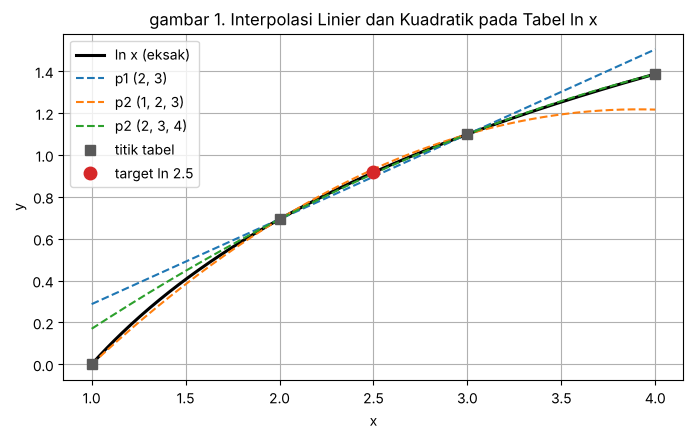

In [5]:
# I.4 gambar 1. tiga polinom terhadap ln x
xs = np.linspace(1.0, 4.0, 300)
plt.figure(figsize=(8, 4.5))
plt.plot(xs, np.log(xs), color="k", lw=2.2, label="ln x (eksak)")
plt.plot(xs, [interpolasi_linier(2.0, 0.6931, 3.0, 1.0986, t) for t in xs], "--", label="p1 (2, 3)")
plt.plot(xs, [newton_kuadratik([1.0, 2.0, 3.0], [0.0, 0.6931, 1.0986], t) for t in xs], "--", label="p2 (1, 2, 3)")
plt.plot(xs, [newton_kuadratik([2.0, 3.0, 4.0], [0.6931, 1.0986, 1.3863], t) for t in xs], "--", label="p2 (2, 3, 4)")
plt.plot(x_tabel, y_tabel, "s", ms=7, color="0.35", label="titik tabel")
plt.plot([2.5], [eksak], "o", ms=9, color="tab:red", label="target ln 2.5")
plt.xlabel("x")
plt.ylabel("y")
plt.title("gambar 1. Interpolasi Linier dan Kuadratik pada Tabel ln x")
plt.legend()
plt.grid(True)
plt.show()

### lesson learnt task I

1. interpolasi linier memberi 0.895850 dengan galat 2.04e-02 (2.23 persen). kedua parabola sama-sama berderajat dua, tetapi trio (1, 2, 3) memberi 0.931800 dengan galat 1.55e-02, sedangkan trio (2, 3, 4) memberi 0.910575 dengan galat 5.72e-03. hasil ini sama dengan Tabel 4 modul. menambah satu titik hanya memangkas galat linier sebesar 24 persen bila titiknya (1, 2, 3), tetapi 72 persen bila titiknya (2, 3, 4). jadi memperbanyak titik tidak otomatis memperbaiki taksiran

2. petunjuk modul mengaitkan perbedaan ini dengan Q3(x). ternyata pada x = 2.5 nilai |Q3| kedua trio sama persis, yaitu 0.375, karena 2.5 berjarak 0.5 dan 1.5 dari titik-titik kedua trio. jadi perbedaannya berasal dari faktor lain di rumus galat, yaitu f'''(c) = 2/c^3. bila rumus galat dibalik, trio (1, 2, 3) memerlukan f'''(c) = 0.2488 (c = 2.003), sedangkan trio (2, 3, 4) hanya 0.0910 (c = 2.801). ln x paling melengkung di dekat x = 1, sehingga trio yang memuat x = 1 ikut membawa turunan ketiga yang besar. menurut saya ciri trio terbaik ada dua: titiknya mengapit target sedekat mungkin (agar |Q| kecil), dan berada di bagian fungsi yang paling landai. pada gambar 1 akibatnya terlihat jelas: p2 (1, 2, 3) sudah menyimpang ke 1.22 di x = 4, padahal ln 4 = 1.386

3. kolom "galat (data eksak)" mengulang perhitungan dengan nilai ln x tanpa pembulatan. hasilnya hampir sama: 2.0411e-02 lawan 2.0441e-02, 1.5549e-02 lawan 1.5509e-02, dan 5.6881e-03 lawan 5.7157e-03. selisihnya paling besar 4e-05, sesuai dengan galat pembulatan 4 desimal yang paling besar 5e-05. pada tabel ini galat interpolasi masih jauh lebih besar dari galat data. pembulatan baru menjadi batas bila galat interpolasinya turun mendekati 1e-05, dan menambah derajat tidak bisa memperbaiki batas itu

---
# Task II: Polinom Lagrange

keempat titik tabel dipakai sekaligus lewat basis kardinal L_i(x). sebelum dipakai, polinomnya diuji harus melewati semua titik data

In [6]:
# II.1 polinom Lagrange untuk n + 1 titik sebarang
def lagrange(xs, ys, x):
    """p_n(x): polinom Lagrange untuk titik-titik (xs, ys)."""
    n = len(xs)
    jumlah = 0.0
    for i in range(n):
        L = 1.0
        for j in range(n):
            if j != i:
                L *= (x - xs[j]) / (xs[i] - xs[j])
        jumlah += ys[i] * L
    return jumlah

print("uji melewati titik data:")
for i in range(4):
    print(f"  p3({x_tabel[i]}) = {lagrange(x_tabel, y_tabel, x_tabel[i]):.4f}  (harus {y_tabel[i]:.4f})")

p3 = lagrange(x_tabel, y_tabel, 2.5)
print(f"\np3(2.5) = {p3:.7f}   Ea = {abs(eksak - p3):.4e}   (p3 - eksak = {p3 - eksak:+.4e})")

uji melewati titik data:
  p3(1.0) = 0.0000  (harus 0.0000)
  p3(2.0) = 0.6931  (harus 0.6931)
  p3(3.0) = 1.0986  (harus 1.0986)
  p3(4.0) = 1.3863  (harus 1.3863)

p3(2.5) = 0.9211875   Ea = 4.8968e-03   (p3 - eksak = +4.8968e-03)


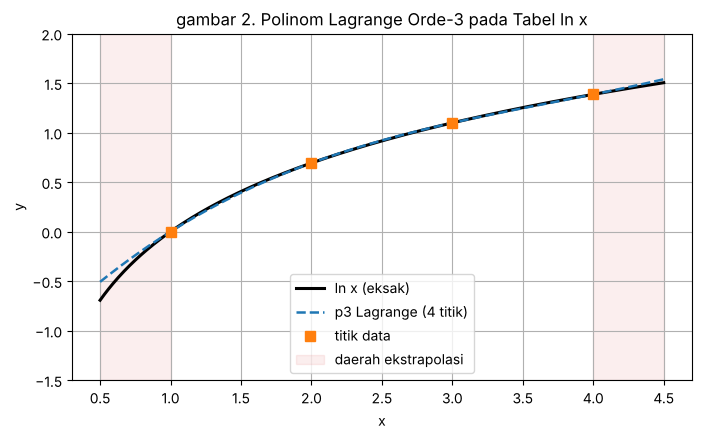

    x      ln x     p3(x)      galat   |Q4(x)|
 0.25  -1.38629  -0.81071  5.756e-01   13.5352
  0.5  -0.69315  -0.50746  1.857e-01    6.5625
  1.5   0.40547   0.39311  1.235e-02    0.9375
  2.5   0.91629   0.92119  4.897e-03    0.5625
  3.5   1.25276   1.24656  6.200e-03    0.9375
  4.5   1.50408   1.53904  3.496e-02    6.5625
  5.0   1.60944   1.72600  1.166e-01   24.0000
  6.0   1.79176   2.28750  4.957e-01  120.0000


In [7]:
# II.2 gambar 2. polinom orde-3 di dalam dan di luar rentang data
xs = np.linspace(0.5, 4.5, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(xs, np.log(xs), color="k", lw=2.2, label="ln x (eksak)")
plt.plot(xs, [lagrange(x_tabel, y_tabel, t) for t in xs], "--", lw=1.8, label="p3 Lagrange (4 titik)")
plt.plot(x_tabel, y_tabel, "s", ms=7, color="tab:orange", label="titik data")
plt.axvspan(0.5, 1.0, color="tab:red", alpha=0.08, label="daerah ekstrapolasi")
plt.axvspan(4.0, 4.5, color="tab:red", alpha=0.08)
plt.ylim(-1.5, 2.0)
plt.xlabel("x")
plt.ylabel("y")
plt.title("gambar 2. Polinom Lagrange Orde-3 pada Tabel ln x")
plt.legend()
plt.grid(True)
plt.show()

print(f"{'x':>5}{'ln x':>10}{'p3(x)':>10}{'galat':>11}{'|Q4(x)|':>10}")
for t in [0.25, 0.5, 1.5, 2.5, 3.5, 4.5, 5.0, 6.0]:
    print(f"{t:>5}{math.log(t):>10.5f}{lagrange(x_tabel, y_tabel, t):>10.5f}"
          f"{abs(math.log(t) - lagrange(x_tabel, y_tabel, t)):>11.3e}{abs(Q(x_tabel, t)):>10.4f}")

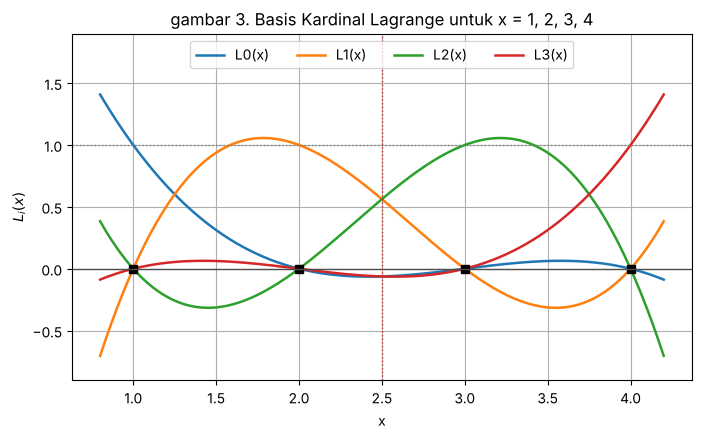

bobot L_i(2.5) = [-0.0625, 0.5625, 0.5625, -0.0625]  jumlah = 1.0
kontribusi y_i L_i(2.5) = [-0.0, 0.3898688, 0.6179625, -0.0866438]


In [8]:
# II.3 gambar 3. basis kardinal L_i(x): bernilai 1 di titiknya sendiri dan 0 di titik lain
def basis(xs, i, x):
    L = 1.0
    for j in range(len(xs)):
        if j != i:
            L *= (x - xs[j]) / (xs[i] - xs[j])
    return L

xs = np.linspace(0.8, 4.2, 300)
plt.figure(figsize=(8, 4.5))
for i in range(4):
    plt.plot(xs, [basis(x_tabel, i, t) for t in xs], lw=1.8, label=f"L{i}(x)")
plt.plot(x_tabel, [0] * 4, "ks", ms=6)
plt.axhline(1, color="0.5", ls=":", lw=1)
plt.axhline(0, color="0.3", lw=1)
plt.axvline(2.5, color="tab:red", ls=":", lw=1)
plt.xlabel("x")
plt.ylabel(r"$L_i(x)$")
plt.title("gambar 3. Basis Kardinal Lagrange untuk x = 1, 2, 3, 4")
plt.ylim(-0.9, 1.9)
plt.legend(loc="upper center", ncol=4)
plt.grid(True)
plt.show()

bobot = [basis(x_tabel, i, 2.5) for i in range(4)]
print("bobot L_i(2.5) =", bobot, " jumlah =", sum(bobot))
print("kontribusi y_i L_i(2.5) =", [round(y_tabel[i] * bobot[i], 7) for i in range(4)])

### lesson learnt task II

1. p3 tepat melewati keempat titik data, dan p3(2.5) = 0.9211875 dengan galat 4.90e-03. taksirannya berada di atas nilai eksak. verifikasi p3(x_i) = y_i penting karena di titik data jawabannya sudah pasti diketahui. kesalahan kecil di kode, misalnya syarat `j != i` yang tertukar, bisa tetap menghasilkan angka yang tampak wajar di x = 2.5, tetapi pasti gagal pada uji ini

2. bobot basis di x = 2.5 adalah (-0.0625, 0.5625, 0.5625, -0.0625) dengan jumlah tepat 1. dua titik terdekat menyumbang paling banyak, sedangkan dua titik terluar mendapat bobot negatif kecil. gambar 3 memperlihatkan sifat basis kardinal: L_i bernilai 1 di titiknya sendiri dan 0 di tiga titik lain

3. galat di dalam rentang [1, 4] paling besar 1.24e-02 (di x = 1.5), tetapi di luar rentang galatnya naik cepat: 3.50e-02 di x = 4.5, 1.17e-01 di x = 5, dan 4.96e-01 di x = 6. kenaikan ini mengikuti |Q4(x)|, yaitu 0.5625 di x = 2.5, 6.56 di x = 4.5, 24 di x = 5, dan 120 di x = 6. di luar rentang data, setiap faktor (x - x_i) tumbuh bersamaan dan tidak ada lagi faktor kecil yang menahannya. di sisi kiri galatnya lebih parah (1.86e-01 di x = 0.5 dibanding 3.50e-02 di x = 4.5, padahal |Q4| keduanya 6.56), karena turunan keempat ln x, yaitu -6/x^4, membesar cepat ketika x mendekati 0

4. dari tiga ke empat titik, galat hanya turun dari 5.72e-03 menjadi 4.90e-03, atau 14 persen, karena titik tambahannya x = 1, bagian yang paling melengkung. menurut saya menambah titik sepadan bila titik baru berada dekat target dan fungsinya mulus di sana. bila titik baru jauh dari target atau berada di daerah yang curam, hasilnya hanya sedikit lebih baik dan bisa juga lebih buruk, seperti terlihat di Soal 1

---
# Task III: Polinom Newton dan Selisih Terbagi

koefisien dihitung sekali lewat tabel segitiga. menambah satu titik hanya menambah satu diagonal baru, sedangkan koefisien lama tetap terpakai

In [9]:
# III.1 tabel selisih terbagi dan evaluasi polinom Newton
def tabel_selisih_terbagi(xs, ys):
    """matriks segitiga ST; kolom j menyimpan selisih terbagi orde j."""
    n = len(xs)
    ST = np.zeros((n, n))
    ST[:, 0] = ys
    for j in range(1, n):
        for i in range(n - j):
            ST[i, j] = (ST[i + 1, j - 1] - ST[i, j - 1]) / (xs[i + j] - xs[i])
    return ST

def newton_polinom(ST, xs, x):
    """evaluasi p_n(x) dari baris pertama tabel selisih terbagi."""
    jumlah = ST[0, 0]
    faktor = 1.0
    for j in range(1, len(xs)):
        faktor *= (x - xs[j - 1])
        jumlah += ST[0, j] * faktor
    return jumlah

ST = tabel_selisih_terbagi(x_tabel, y_tabel)
print(f"{'x':>6}{'f[x]':>9}{'orde 1':>10}{'orde 2':>11}{'orde 3':>11}")
for i in range(4):
    sel = "".join(f"{ST[i, j]:>{10 if j == 1 else 11}.4f}" for j in range(1, 4 - i))
    print(f"{x_tabel[i]:>6.1f}{ST[i, 0]:>9.4f}{sel}")
p3_newton = newton_polinom(ST, x_tabel, 2.5)
print(f"\np3 Newton   (2.5) = {p3_newton:.7f}   Ea = {abs(eksak - p3_newton):.4e}")
print(f"p3 Lagrange (2.5) = {p3:.7f}")
print(f"selisih Newton - Lagrange = {p3_newton - p3:.2e}")
selisih_maks = max(abs(newton_polinom(ST, x_tabel, t) - lagrange(x_tabel, y_tabel, t)) for t in np.linspace(0.5, 4.5, 401))
print(f"selisih terbesar pada 401 titik di [0.5, 4.5] = {selisih_maks:.2e}")

     x     f[x]    orde 1     orde 2     orde 3
   1.0   0.0000    0.6931    -0.1438     0.0283
   2.0   0.6931    0.4055    -0.0589
   3.0   1.0986    0.2877
   4.0   1.3863

p3 Newton   (2.5) = 0.9211875   Ea = 4.8968e-03
p3 Lagrange (2.5) = 0.9211875
selisih Newton - Lagrange = 0.00e+00
selisih terbesar pada 401 titik di [0.5, 4.5] = 6.66e-16


In [10]:
# III.2 menambah titik kelima x4 = 5, ln 5 = 1.6094
x5 = x_tabel + [5.0]
y5 = y_tabel + [1.6094]
ST5 = tabel_selisih_terbagi(x5, y5)

print("koefisien (baris pertama tabel):")
for j in range(5):
    lama = f"{ST[0, j]:.6f}" if j < 4 else "-"
    print(f"  f[x0..x{j}] baru = {ST5[0, j]:+.6f}   lama = {lama}")

p4 = newton_polinom(ST5, x5, 2.5)
print(f"\np4(2.5) = {p4:.7f}   Ea = {abs(eksak - p4):.4e}")
q4 = Q(x_tabel, 2.5)
print(f"Q4(2.5) = {q4}")
print(f"suku baru f[x0..x4] * Q4(2.5) = {ST5[0, 4] * q4:+.6e}")
print(f"p4 - p3                       = {p4 - p3:+.6e}")
print(f"galat aktual p3: ln 2.5 - p3  = {eksak - p3:+.6e}")

koefisien (baris pertama tabel):
  f[x0..x0] baru = +0.000000   lama = 0.000000
  f[x0..x1] baru = +0.693100   lama = 0.693100
  f[x0..x2] baru = -0.143800   lama = -0.143800
  f[x0..x3] baru = +0.028300   lama = 0.028300
  f[x0..x4] baru = -0.004858   lama = -

p4(2.5) = 0.9184547   Ea = 2.1640e-03
Q4(2.5) = 0.5625
suku baru f[x0..x4] * Q4(2.5) = -2.732813e-03
p4 - p3                       = -2.732813e-03
galat aktual p3: ln 2.5 - p3  = -4.896768e-03


In [11]:
# III.3 data datang satu per satu: Newton menambah satu koefisien, Lagrange menghitung ulang
def tambah_titik(xs, diag, x_baru, y_baru):
    """perbarui diagonal bawah tabel (f[x_k], f[x_k-1, x_k], ...) dan kembalikan koefisien baru.

    diag menyimpan selisih terbagi yang berakhir di titik terakhir. hanya len(xs) pembagian
    yang dibutuhkan untuk menampung satu titik baru.
    """
    baru = [y_baru]
    for j in range(len(diag)):
        baru.append((baru[j] - diag[j]) / (x_baru - xs[len(xs) - 1 - j]))
    xs.append(x_baru)
    return baru, baru[-1]

xs_stream, diag, koef = [], [], []
ops_newton = 0
print(f"{'titik ke':>9}{'x baru':>8}{'koef baru':>12}{'p(2.5)':>11}{'galat':>11}{'bagi Newton':>13}{'bagi Lagrange':>15}")
for k, (xb, yb) in enumerate(zip(x5, y5)):
    ops = len(xs_stream)
    diag, c = tambah_titik(xs_stream, diag, xb, yb)
    koef.append(c)
    ops_newton += ops
    nilai = koef[0]
    faktor = 1.0
    for j in range(1, len(koef)):
        faktor *= (2.5 - xs_stream[j - 1])
        nilai += koef[j] * faktor
    n_titik = k + 1
    print(f"{n_titik:>9}{xb:>8.1f}{c:>+12.6f}{nilai:>11.7f}{abs(eksak - nilai):>11.3e}{ops:>13}{n_titik * (n_titik - 1):>15}")
print("koefisien hasil streaming sama dengan ST5[0]:", np.allclose(koef, ST5[0]))

 titik ke  x baru   koef baru     p(2.5)      galat  bagi Newton  bagi Lagrange
        1     1.0   +0.000000  0.0000000  9.163e-01            0              0
        2     2.0   +0.693100  1.0396500  1.234e-01            1              2
        3     3.0   -0.143800  0.9318000  1.551e-02            2              6
        4     4.0   +0.028300  0.9211875  4.897e-03            3             12
        5     5.0   -0.004858  0.9184547  2.164e-03            4             20
koefisien hasil streaming sama dengan ST5[0]: True


### lesson learnt task III

1. tabel selisih terbagi sama dengan Tabel 5 modul, dengan koefisien 0, 0.6931, -0.1438, dan 0.0283. polinom Newton memberi p3(2.5) = 0.9211875, sama dengan Lagrange dengan selisih 0 di x = 2.5 dan paling besar 6.66e-16 pada 401 titik di [0.5, 4.5]. selisih sebesar itu hanya pembulatan, sehingga keduanya memang polinom yang sama, sesuai teorema keunikan

2. setelah titik x = 5 ditambahkan, keempat koefisien lama tidak berubah dan hanya satu koefisien baru yang muncul, yaitu -0.004858. p4(2.5) = 0.9184547 dengan galat 2.16e-03. tabel streaming di III.3 menunjukkan biayanya: Newton memerlukan 1, 2, 3, lalu 4 pembagian ketika titik ke-2 sampai ke-5 datang, total 10 pembagian. Lagrange tidak menyimpan apa-apa, sehingga setiap evaluasi menghitung ulang semua bobot dengan n(n - 1) pembagian, yaitu 2, 6, 12, lalu 20

3. besar koefisien turun sekitar lima kali tiap orde (0.6931, 0.1438, 0.0283, 0.0049) dengan tanda bergantian. pola ini sesuai dengan f[x0..xk] = f^(k)(xi)/k!, karena untuk ln x nilainya (-1)^(k-1)/(k xi^k), yang bergantian tanda dan mengecil. koefisien baru juga meramalkan arah galat p3: f[x0..x4] Q4(2.5) = -2.73e-03 bernilai negatif, artinya p3 terlalu tinggi. galat sebenarnya -4.90e-03, jadi tandanya benar tetapi besarnya hanya 56 persen. suku itu persis sama dengan p4 - p3, sehingga sisa galat p4 (2.16e-03) adalah bagian yang belum tertangkap suku baru

4. untuk data yang terus bertambah, misalnya sensor yang mengirim satu nilai per detik, Newton cukup menyimpan diagonal terakhir tabel dan menambah satu koefisien dengan n pembagian. koefisien lama tetap berlaku, sehingga taksiran bisa diperbarui tanpa mengulang dari awal

---
# Task IV: Galat Interpolasi dan Fenomena Runge

rumus galat E(x) = f^(n+1)(c) Q_{n+1}(x)/(n+1)! diuji dulu pada ln x, lalu derajat polinom dinaikkan pada fungsi Runge dengan dua penataan titik: berjarak sama dan Chebyshev

In [12]:
# IV.1 verifikasi rumus galat pada ln x dengan data eksak (tanpa pembulatan 4 desimal)
# turunan keempat ln x adalah -6/x^4, sehingga |f''''| pada [1, 4] berada di antara 6/256 dan 6
grid_ln = np.linspace(1.0, 4.0, 601)
lolos = True
print(f"{'x':>5}{'|E| aktual':>12}{'batas bawah':>13}{'batas atas':>12}")
for t in grid_ln:
    E = abs(math.log(t) - lagrange(x_tabel, y_eksak, t))
    bawah = (6 / 4**4) / 24 * abs(Q(x_tabel, t))
    atas = 6 / 24 * abs(Q(x_tabel, t))
    if not (bawah - 1e-15 <= E <= atas + 1e-15):
        lolos = False
    if t in (1.25, 1.5, 2.5, 3.5, 3.75):
        print(f"{t:>5}{E:>12.4e}{bawah:>13.4e}{atas:>12.4e}")
print("semua 601 titik berada di antara batas bawah dan atas:", lolos)
E25 = math.log(2.5) - lagrange(x_tabel, y_eksak, 2.5)
c25 = (6 / (abs(E25) * 24 / abs(Q(x_tabel, 2.5)))) ** 0.25
print(f"\ngalat di 2.5 dengan data eksak = {E25:+.4e}, sehingga c yang memenuhi rumus = {c25:.4f}")

    x  |E| aktual  batas bawah  batas atas
 1.25  1.3595e-02   8.8120e-04  2.2559e-01
  1.5  1.2313e-02   9.1553e-04  2.3438e-01
  2.5  4.9306e-03   5.4932e-04  1.4062e-01
  3.5  6.2055e-03   9.1553e-04  2.3438e-01
 3.75  5.6312e-03   8.8120e-04  2.2559e-01
semua 601 titik berada di antara batas bawah dan atas: True

galat di 2.5 dengan data eksak = -4.9306e-03, sehingga c yang memenuhi rumus = 2.3110


In [13]:
# IV.2 galat maksimum fungsi Runge: titik berjarak sama dibanding titik Chebyshev
runge = lambda x: 1.0 / (1.0 + 25.0 * x * x)
grid = np.linspace(-1.0, 1.0, 2001)               # kisi pengamat, bukan titik data

def titik_sama(n):
    return np.linspace(-1.0, 1.0, n + 1)

def titik_cheb(n):
    return np.cos((2 * np.arange(n + 1) + 1) * np.pi / (2 * n + 2))

def galat_maks(xd):
    yd = runge(xd)
    return max(abs(runge(t) - lagrange(xd, yd, t)) for t in grid)

print(f"{'n':>3}{'jarak-sama':>13}{'Chebyshev':>12}")
for n in [2, 4, 8, 12, 16]:
    print(f"{n:>3}{galat_maks(titik_sama(n)):>13.4e}{galat_maks(titik_cheb(n)):>12.4e}")

  n   jarak-sama   Chebyshev
  2   6.4623e-01  6.0060e-01
  4   4.3836e-01  4.0202e-01
  8   1.0452e+00  1.7083e-01


 12   3.6633e+00  6.9216e-02


 16   1.4394e+01  3.2613e-02


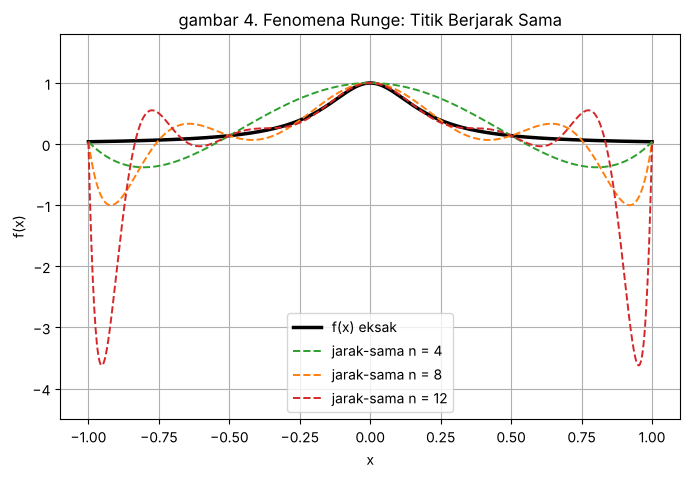

n = 12 jarak-sama: galat terbesar di x = +0.953, p12 = -3.6211, f = 0.0422
galat maksimum di |x| <= 0.5 : 6.1005e-02
galat maksimum di |x| >  0.5 : 3.6633e+00


In [14]:
# IV.3 gambar 4. polinom jarak-sama derajat 4, 8, 12
xs = np.linspace(-1.0, 1.0, 800)
plt.figure(figsize=(8, 5))
plt.plot(xs, runge(xs), color="k", lw=2.5, label="f(x) eksak")
for n, warna in [(4, "tab:green"), (8, "tab:orange"), (12, "tab:red")]:
    xe = titik_sama(n)
    plt.plot(xs, [lagrange(xe, runge(xe), t) for t in xs], "--", lw=1.4, color=warna, label=f"jarak-sama n = {n}")
plt.ylim(-4.5, 1.8)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("gambar 4. Fenomena Runge: Titik Berjarak Sama")
plt.legend()
plt.grid(True)
plt.show()

xe = titik_sama(12)
p12 = np.array([lagrange(xe, runge(xe), t) for t in grid])
k = np.argmax(np.abs(p12 - runge(grid)))
print(f"n = 12 jarak-sama: galat terbesar di x = {grid[k]:+.3f}, p12 = {p12[k]:.4f}, f = {runge(grid[k]):.4f}")
tengah = np.abs(grid) <= 0.5
print(f"galat maksimum di |x| <= 0.5 : {np.abs(p12 - runge(grid))[tengah].max():.4e}")
print(f"galat maksimum di |x| >  0.5 : {np.abs(p12 - runge(grid))[~tengah].max():.4e}")

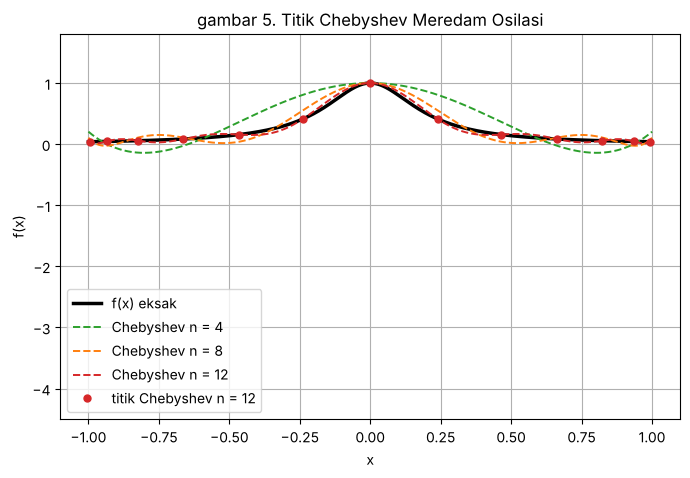

In [15]:
# IV.4 gambar 5. polinom Chebyshev derajat 4, 8, 12
plt.figure(figsize=(8, 5))
plt.plot(xs, runge(xs), color="k", lw=2.5, label="f(x) eksak")
for n, warna in [(4, "tab:green"), (8, "tab:orange"), (12, "tab:red")]:
    xc = titik_cheb(n)
    plt.plot(xs, [lagrange(xc, runge(xc), t) for t in xs], "--", lw=1.4, color=warna, label=f"Chebyshev n = {n}")
xc = titik_cheb(12)
plt.plot(xc, runge(xc), "o", ms=5, color="tab:red", label="titik Chebyshev n = 12")
plt.ylim(-4.5, 1.8)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("gambar 5. Titik Chebyshev Meredam Osilasi")
plt.legend()
plt.grid(True)
plt.show()

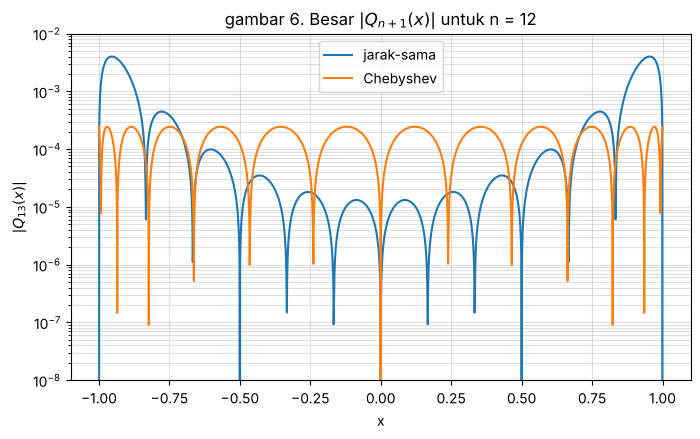

max |Q13| jarak-sama = 4.0078e-03 di x = +0.954
max |Q13| Chebyshev  = 2.4414e-04   (teori 2^-12 = 2.4414e-04)
max |Q13| jarak-sama di |x| <= 0.2 = 1.3145e-05
rasio maksimum = 16.4


In [16]:
# IV.5 gambar 6. |Q_{n+1}(x)| untuk n = 12: sumber perbedaan kedua penataan titik
n = 12
Qe = np.array([abs(Q(titik_sama(n), t)) for t in grid])
Qc = np.array([abs(Q(titik_cheb(n), t)) for t in grid])
plt.figure(figsize=(8, 4.5))
plt.semilogy(grid, Qe + 1e-20, label="jarak-sama")
plt.semilogy(grid, Qc + 1e-20, label="Chebyshev")
plt.ylim(1e-8, 1e-2)
plt.xlabel("x")
plt.ylabel(r"$|Q_{13}(x)|$")
plt.title(r"gambar 6. Besar $|Q_{n+1}(x)|$ untuk n = 12")
plt.legend()
plt.grid(True, which="both", alpha=0.4)
plt.show()

print(f"max |Q13| jarak-sama = {Qe.max():.4e} di x = {grid[np.argmax(Qe)]:+.3f}")
print(f"max |Q13| Chebyshev  = {Qc.max():.4e}   (teori 2^-12 = {2.0**-12:.4e})")
print(f"max |Q13| jarak-sama di |x| <= 0.2 = {Qe[np.abs(grid) <= 0.2].max():.4e}")
print(f"rasio maksimum = {Qe.max() / Qc.max():.1f}")

### lesson learnt task IV

1. rumus galat lolos uji pada ln x dengan data eksak. di 601 titik pada [1, 4], galat aktual selalu berada di antara batas yang dihitung dengan min |f''''| = 6/256 dan max |f''''| = 6. di x = 2.5 galatnya 4.93e-03 dengan batas 5.49e-04 sampai 1.41e-01, dan c yang membuat rumusnya tepat adalah 2.311. batas atasnya 28 kali lebih besar dari galat aktual karena |f''''| berubah 256 kali lipat di sepanjang [1, 4]. jadi batas ini aman, tetapi longgar

2. tabel Runge sama dengan Tabel 6 modul. dengan titik berjarak sama, galat turun dari 0.646 (n = 2) ke 0.438 (n = 4), lalu naik lagi menjadi 1.045, 3.663, dan 14.39 pada n = 8, 12, dan 16. dengan titik Chebyshev galatnya terus turun: 0.601, 0.402, 0.171, 0.069, dan 0.033. jadi anggapan "derajat lebih tinggi pasti lebih akurat" tidak berlaku untuk fungsi yang turunan tingginya tumbuh cepat. untuk fungsi Runge, turunan ke-k di x = 0 sebesar k! 5^k untuk k genap (dari deret 1 - 25x^2 + 625x^4 - ...). setelah dibagi (n+1)! di rumus galat, masih tersisa faktor sekitar 5^(n+1) yang terus membesar, sehingga galat hanya turun bila |Q(x)| mengecil lebih cepat dari itu

3. gambar 4 dan angka di IV.3 menunjukkan lokasi masalahnya. pada n = 12 jarak-sama, galat terbesar ada di x = 0.953, ketika p12 = -3.62 padahal f = 0.042. di |x| <= 0.5 galatnya hanya 0.061, sedangkan di luar itu 3.66. gambar 6 menjelaskan alasannya: |Q13| titik jarak-sama mencapai 4.0e-03 di dekat ujung (x = 0.954) dan hanya 1.3e-05 di tengah, berbeda 300 kali. titik Chebyshev meratakan |Q13| sehingga semua puncaknya setinggi 2.44e-04 = 2^-12, sama dengan teori. puncak tertingginya 16.4 kali lebih rendah dari titik jarak-sama

4. ada dua jalan keluar. titik Chebyshev terbukti di sini, tetapi hanya bisa dipakai bila kita bebas memilih lokasi sampel. bila datanya sudah berjarak sama, misalnya sensor dengan interval tetap, jalan keluar yang disebut modul adalah spline: rentang dipotong-potong dan tiap potongan memakai polinom derajat rendah

---
# Kesimpulan Praktikum

| cara | titik | taksiran ln 2.5 | galat | catatan |
|---|---|---|---|---|
| linier | 2, 3 | 0.895850 | 2.04e-02 | hanya memakai kemiringan |
| kuadratik | 1, 2, 3 | 0.931800 | 1.55e-02 | memuat x = 1 yang paling melengkung |
| kuadratik | 2, 3, 4 | 0.910575 | 5.72e-03 | \|Q3(2.5)\| sama, f''' lebih kecil |
| Lagrange | 1, 2, 3, 4 | 0.9211875 | 4.90e-03 | rumus simetris |
| Newton | 1, 2, 3, 4 | 0.9211875 | 4.90e-03 | identik dengan Lagrange |
| Newton | 1, ..., 5 | 0.9184547 | 2.16e-03 | cukup satu koefisien baru |

temuan dari keempat task:

1. Lagrange dan Newton menghasilkan polinom yang sama (selisih paling besar 6.66e-16). perbedaannya hanya di cara menulis dan biaya: Newton cukup menambah satu koefisien ketika ada titik baru
2. pemilihan titik sama pentingnya dengan derajat. dua trio dengan |Q3(2.5)| yang sama memberi galat berbeda hampir tiga kali lipat karena kelengkungan ln x di dekat x = 1
3. rumus galat E(x) = f^(n+1)(c) Q(x)/(n+1)! terbukti memberi batas yang benar di 601 titik, dan |Q(x)| menjelaskan mengapa ekstrapolasi (galat 0.496 di x = 6) jauh lebih berbahaya daripada interpolasi
4. menaikkan derajat dengan titik berjarak sama bisa membuat galat membesar tanpa batas (14.39 pada n = 16 untuk fungsi Runge). titik Chebyshev atau spline adalah jalan keluarnya

---
---
# BAGIAN III.8 - Tugas Praktikum

## Soal 1. Tabel akar kuadrat

tabel {0 -> 0, 1 -> 1, 4 -> 2, 9 -> 3}. taksir sqrt(3) dan sqrt(5) dengan interpolasi linier (dua titik terdekat) dan Lagrange kubik (empat titik), bandingkan dengan nilai eksak, dan hitung galat relatif tiap taksiran

  t     eksak   linier  Er linier    kubik  Er kubik
  3  1.732051   1.6667      3.77%   1.9000     9.70%
  5  2.236068   2.2000      1.61%   2.0000    10.56%

bentuk kubiknya: p3(x) = [ 0.016667 -0.25      1.233333  0.      ] (koefisien x^3, x^2, x, 1)
galat maksimum kubik pada [0, 9] = 0.5458
turunan sqrt(x) di x = 0.01, 1, 4: [5.0, 0.5, 0.25]


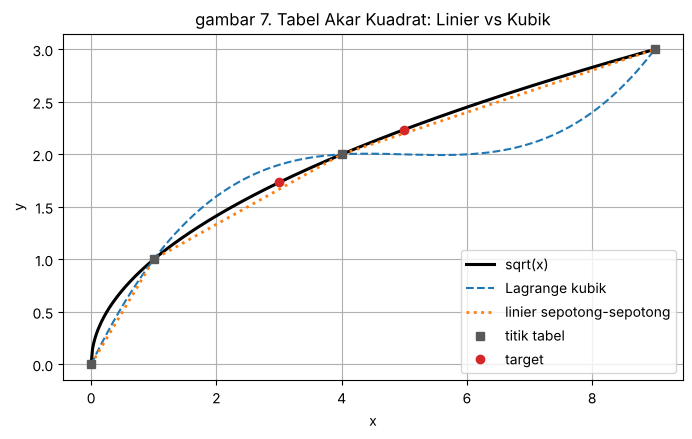

In [17]:
# Soal 1. akar kuadrat dari tabel kuadrat sempurna
xs_akar = [0.0, 1.0, 4.0, 9.0]
ys_akar = [0.0, 1.0, 2.0, 3.0]

def linier_tabel(xs, ys, t):
    """interpolasi linier pada dua titik yang mengapit t."""
    for k in range(len(xs) - 1):
        if xs[k] <= t <= xs[k + 1]:
            return interpolasi_linier(xs[k], ys[k], xs[k + 1], ys[k + 1], t)
    raise ValueError("t di luar tabel")

print(f"{'t':>3}{'eksak':>10}{'linier':>9}{'Er linier':>11}{'kubik':>9}{'Er kubik':>10}")
for t in [3.0, 5.0]:
    e = math.sqrt(t)
    lin = linier_tabel(xs_akar, ys_akar, t)
    kub = lagrange(xs_akar, ys_akar, t)
    print(f"{t:>3.0f}{e:>10.6f}{lin:>9.4f}{abs(e - lin) / e * 100:>10.2f}%{kub:>9.4f}{abs(e - kub) / e * 100:>9.2f}%")

print()
xs = np.linspace(0, 9, 400)
p_kubik = [lagrange(xs_akar, ys_akar, t) for t in xs]
print("bentuk kubiknya: p3(x) =", np.round(np.polyfit(xs_akar, ys_akar, 3), 6), "(koefisien x^3, x^2, x, 1)")
print(f"galat maksimum kubik pada [0, 9] = {max(abs(math.sqrt(t) - p) for t, p in zip(xs, p_kubik)):.4f}")
print("turunan sqrt(x) di x = 0.01, 1, 4:", [round(0.5 / math.sqrt(t), 3) for t in [0.01, 1, 4]])

plt.figure(figsize=(8, 4.5))
plt.plot(xs, np.sqrt(xs), "k", lw=2.2, label="sqrt(x)")
plt.plot(xs, p_kubik, "--", label="Lagrange kubik")
plt.plot(xs, [linier_tabel(xs_akar, ys_akar, t) for t in xs], ":", lw=2, label="linier sepotong-sepotong")
plt.plot(xs_akar, ys_akar, "s", color="0.35", label="titik tabel")
plt.plot([3, 5], [math.sqrt(3), math.sqrt(5)], "o", color="tab:red", label="target")
plt.xlabel("x")
plt.ylabel("y")
plt.title("gambar 7. Tabel Akar Kuadrat: Linier vs Kubik")
plt.legend()
plt.grid(True)
plt.show()

### jawaban soal 1

| x | eksak | linier | galat relatif | Lagrange kubik | galat relatif |
|---|---|---|---|---|---|
| 3 | 1.732051 | 1.6667 | 3.77% | 1.9000 | 9.70% |
| 5 | 2.236068 | 2.2000 | 1.61% | 2.0000 | 10.56% |

kubik kalah dari linier di kedua titik. polinomnya p3(x) = 0.016667x^3 - 0.25x^2 + 1.233333x, dipaksa melewati (0, 0) tempat sqrt(x) punya kemiringan tak hingga. untuk naik cepat dari 0 ke 1 lalu tetap melewati (4, 2) dan (9, 3), kubik melampaui sqrt(x) di [1, 4] (1.9 di x = 3) lalu nyaris datar di [4, 6] (2.0 di x = 5). gambar 7 memperlihatkan lekukan itu, dengan galat maksimum 0.546 pada [0, 9].

ada dua penyebab. pertama, jarak antar titiknya tidak seragam (1, 3, lalu 5), sehingga |Q4| di dalam celah lebar menjadi besar, misalnya |Q4(5)| = 5 x 4 x 1 x 4 = 80. kedua, turunan sqrt(x) membesar tanpa batas di dekat nol (5.0 di x = 0.01, padahal 0.25 di x = 4). rumus galat bahkan tidak berlaku di sini, karena sqrt(x) tidak punya turunan di x = 0. interpolasi linier hanya memakai dua titik terdekat, sehingga perilaku curam di dekat nol tidak ikut memengaruhi taksiran di x = 3 dan x = 5.

## Soal 2. Interpolasi terbalik

dari tabel ln x, tentukan x sehingga ln x = 0.9 dengan interpolasi terbalik linier dan kuadratik, lalu bandingkan dengan e^0.9 = 2.459603

In [18]:
# Soal 2. interpolasi terbalik: data (y_i, x_i), dievaluasi di y target
def terbalik(xs, ys, y_target):
    """kembalikan (taksiran linier, taksiran kuadratik) untuk x dengan f(x) = y_target.

    linier memakai dua titik yang mengapit y_target. kuadratik memakai titik k-1, k, k+1
    dengan k indeks kiri pengapit, digeser bila menyentuh ujung tabel.
    """
    n = len(xs)
    k = next(i for i in range(n - 1) if min(ys[i], ys[i + 1]) <= y_target <= max(ys[i], ys[i + 1]))
    lin = interpolasi_linier(ys[k], xs[k], ys[k + 1], xs[k + 1], y_target)
    m = min(max(k - 1, 0), n - 3)
    kua = newton_kuadratik(ys[m:m + 3], xs[m:m + 3], y_target)
    return lin, kua

x_benar = math.exp(0.9)
lin, kua = terbalik(x_tabel, y_tabel, 0.9)
print(f"eksak e^0.9   = {x_benar:.6f}")
print(f"linier        = {lin:.6f}   Ea = {abs(x_benar - lin):.4e}   Er = {abs(x_benar - lin) / x_benar * 100:.3f}%")
print(f"kuadratik     = {kua:.6f}   Ea = {abs(x_benar - kua):.4e}   Er = {abs(x_benar - kua) / x_benar * 100:.3f}%")
kua2 = newton_kuadratik(y_tabel[1:4], x_tabel[1:4], 0.9)
print(f"kuadratik trio x = 2,3,4 sebagai pembanding = {kua2:.6f}   Ea = {abs(x_benar - kua2):.4e}")

print("\ninterpolasi maju di titik yang setara (x = e^0.9), dengan titik x yang sama:")
maju_lin = interpolasi_linier(2.0, 0.6931, 3.0, 1.0986, x_benar)
maju_kua = newton_kuadratik([1.0, 2.0, 3.0], [0.0, 0.6931, 1.0986], x_benar)
print(f"  linier   : ln x = {maju_lin:.6f}, galat ln = {abs(0.9 - maju_lin):.4e}, setara galat x = {abs(0.9 - maju_lin) * x_benar:.4e}")
print(f"  kuadratik: ln x = {maju_kua:.6f}, galat ln = {abs(0.9 - maju_kua):.4e}, setara galat x = {abs(0.9 - maju_kua) * x_benar:.4e}")

print("\nfungsi balikan x = e^y pada rentang data y in [0.69, 1.10]: turunan kedua e^y bernilai",
      f"{math.exp(0.6931):.3f} sampai {math.exp(1.0986):.3f}, sedangkan |(ln x)''| = 1/x^2 bernilai {1 / 9:.3f} sampai {1 / 4:.3f} pada x in [2, 3]")

print("\ncontoh tidak sah: tabel sin x pada x = 0, 1, 2, 3 tidak monoton, mencari sin x = 0.5")
xs_sin = [0.0, 1.0, 2.0, 3.0]
ys_sin = [math.sin(v) for v in xs_sin]
print("  y tabel:", np.round(ys_sin, 4))
print(f"  balikan kubik pada keempat titik di y = 0.5 : x = {lagrange(ys_sin, xs_sin, 0.5):.4f}")
print(f"  akar sebenarnya: pi/6 = {math.pi / 6:.4f} dan 5pi/6 = {5 * math.pi / 6:.4f}")

eksak e^0.9   = 2.459603
linier        = 2.510234   Ea = 5.0631e-02   Er = 2.059%
kuadratik     = 2.471960   Ea = 1.2357e-02   Er = 0.502%
kuadratik trio x = 2,3,4 sebagai pembanding = 2.450380   Ea = 9.2232e-03

interpolasi maju di titik yang setara (x = e^0.9), dengan titik x yang sama:
  linier   : ln x = 0.879469, galat ln = 2.0531e-02, setara galat x = 5.0498e-02
  kuadratik: ln x = 0.915184, galat ln = 1.5184e-02, setara galat x = 3.7348e-02

fungsi balikan x = e^y pada rentang data y in [0.69, 1.10]: turunan kedua e^y bernilai 2.000 sampai 3.000, sedangkan |(ln x)''| = 1/x^2 bernilai 0.111 sampai 0.250 pada x in [2, 3]

contoh tidak sah: tabel sin x pada x = 0, 1, 2, 3 tidak monoton, mencari sin x = 0.5
  y tabel: [0.     0.8415 0.9093 0.1411]
  balikan kubik pada keempat titik di y = 0.5 : x = 2.0121
  akar sebenarnya: pi/6 = 0.5236 dan 5pi/6 = 2.6180


### jawaban soal 2

| cara | x dengan ln x = 0.9 | galat absolut | galat relatif |
|---|---|---|---|
| terbalik linier | 2.510234 | 5.06e-02 | 2.06% |
| terbalik kuadratik | 2.471960 | 1.24e-02 | 0.50% |
| eksak e^0.9 | 2.459603 | | |

kedua hasil sama dengan petunjuk modul. kuadratik memakai titik x = 1, 2, 3 (titik kiri pengapit beserta tetangga kirinya), sesuai pilihan yang menghasilkan angka kunci. trio x = 2, 3, 4 memberi 2.450380 dengan galat lebih kecil (9.22e-03).

perbandingan dengan interpolasi maju di titik setara (x = e^0.9, titik yang sama):

- linier maju memberi ln x = 0.879469, galatnya 2.05e-02 dalam satuan ln x. galat terbalik linier (5.06e-02) memang lebih besar dalam angka, karena di sekitar x = 2.46 nilai x berubah sekitar 2.46 kali lebih cepat dari ln x (dx/dy = x). bila galat maju diubah ke satuan x, hasilnya 5.05e-02, hampir sama. untuk interpolasi linier ini wajar, karena garis balikan adalah garis hubung yang sama, hanya dibaca dari sumbu lain
- fungsi balikan x = e^y juga lebih melengkung: turunan keduanya bernilai 2.0 sampai 3.0 pada rentang data, sedangkan |(ln x)''| hanya 0.11 sampai 0.25. kelengkungan yang lebih besar ini yang membuat galat terbalik membesar dalam satuan x
- untuk kuadratik, hasil percobaan ini tidak mendukung klaim tersebut. galat terbalik dalam satuan x adalah 1.24e-02, sedangkan galat maju dalam satuan ln x 1.52e-02 dan dalam satuan x 3.73e-02. jadi galat terbalik lebih kecil di kedua perbandingan. jadi menurut saya galat terbalik lebih besar bila diukur dalam satuan x yang berubah lebih cepat, tetapi tidak selalu lebih besar untuk setiap derajat

interpolasi terbalik tidak sah bila fungsinya tidak monoton pada rentang data. contoh di sel kode: tabel sin x pada x = 0, 1, 2, 3 naik lalu turun. balikan kubik di y = 0.5 memberi x = 2.0121, padahal akar sebenarnya pi/6 = 0.5236 dan 5pi/6 = 2.6180. karena dua x memiliki y yang hampir sama (0.8415 dan 0.9093), polinom balikannya tidak mewakili fungsi apa pun. dalam keadaan itu lebih aman mencari akar f(x) - y = 0 pada interval yang monoton, seperti di Modul 3.

## Soal 3. Verifikasi rumus galat

f(x) = sin x dengan titik 0.2 dan 0.4. taksir sin(0.32) secara linier, hitung galat aktual dan batas atas M2/2 |(x - x0)(x - x1)| dengan M2 = max |f''| pada [0.2, 0.4]

In [19]:
# Soal 3. galat aktual sin(0.32) terhadap batas teoretis
x0, x1, t = 0.2, 0.4, 0.32
p = interpolasi_linier(x0, math.sin(x0), x1, math.sin(x1), t)
galat = abs(math.sin(t) - p)
M2 = max(abs(math.sin(v)) for v in np.linspace(x0, x1, 2001))   # |f''| = |sin x|, terbesar di x = 0.4
batas = M2 / 2 * abs((t - x0) * (t - x1))
print(f"p1(0.32)       = {p:.8f}")
print(f"sin(0.32)      = {math.sin(t):.8f}")
print(f"galat aktual   = {galat:.4e}")
print(f"M2 = sin(0.4)  = {M2:.6f}")
print(f"batas atas     = {batas:.4e}")
print(f"galat <= batas : {galat <= batas}")
m2 = math.sin(x0)
print(f"batas bawah (memakai min |f''| = sin 0.2) = {m2 / 2 * abs((t - x0) * (t - x1)):.4e}")
c = math.asin(galat * 2 / abs((t - x0) * (t - x1)))
print(f"c yang membuat rumus galat tepat = {c:.4f}")

p1(0.32)       = 0.31311874
sin(0.32)      = 0.31456656
galat aktual   = 1.4478e-03
M2 = sin(0.4)  = 0.389418
batas atas     = 1.8692e-03
galat <= batas : True
batas bawah (memakai min |f''| = sin 0.2) = 9.5361e-04
c yang membuat rumus galat tepat = 0.3064


### jawaban soal 3

| besaran | nilai |
|---|---|
| p1(0.32) | 0.31311874 |
| sin(0.32) | 0.31456656 |
| galat aktual | 1.4478e-03 |
| M2 = max \|sin x\| = sin 0.4 | 0.389418 |
| batas atas M2/2 \|(x - 0.2)(x - 0.4)\| | 1.8692e-03 |

galat aktual 1.448e-03 tidak melampaui batas atas 1.869e-03, sesuai petunjuk. bila M2 diganti nilai terkecil |f''| = sin 0.2, diperoleh batas bawah 9.54e-04, sehingga galat aktual berada di antara keduanya. titik c yang membuat rumus galat tepat adalah 0.3064, dan nilainya memang berada di dalam [0.2, 0.4]. galatnya positif (sin di atas garis) karena sin x cekung pada rentang ini, sehingga garis hubung selalu berada di bawah kurva.

## Soal 4. Runge lanjutan

perluas tabel Runge untuk n = 6, 10, 14 dengan titik berjarak sama, lalu cari derajat terkecil n dengan titik Chebyshev yang memberi galat maksimum di bawah 0.1

In [20]:
# Soal 4. tabel Runge diperluas dan pencarian n Chebyshev terkecil
print(f"{'n':>3}{'jarak-sama':>13}{'Chebyshev':>12}")
for n in [2, 4, 6, 8, 10, 12, 14, 16]:
    print(f"{n:>3}{galat_maks(titik_sama(n)):>13.4e}{galat_maks(titik_cheb(n)):>12.4e}")

def cari_n_cheb(batas=0.1, n_maks=40):
    """derajat terkecil n dengan galat maksimum Chebyshev di bawah batas."""
    for n in range(1, n_maks + 1):
        e = galat_maks(titik_cheb(n))
        if e < batas:
            return n, e
    return None, None

n_min, e_min = cari_n_cheb(0.1)
print(f"\nderajat terkecil Chebyshev dengan galat < 0.1: n = {n_min}, galat = {e_min:.4e}")
print("galat Chebyshev n = 9 sampai 13:")
for n in range(9, 14):
    print(f"  n = {n:>2}: {galat_maks(titik_cheb(n)):.4e}")

  n   jarak-sama   Chebyshev
  2   6.4623e-01  6.0060e-01
  4   4.3836e-01  4.0202e-01


  6   6.1695e-01  2.6423e-01


  8   1.0452e+00  1.7083e-01


 10   1.9156e+00  1.0915e-01


 12   3.6633e+00  6.9216e-02


 14   7.1949e+00  4.6602e-02


 16   1.4394e+01  3.2613e-02



derajat terkecil Chebyshev dengan galat < 0.1: n = 12, galat = 6.9216e-02
galat Chebyshev n = 9 sampai 13:
  n =  9: 2.6918e-01
  n = 10: 1.0915e-01


  n = 11: 1.8276e-01
  n = 12: 6.9216e-02
  n = 13: 1.2340e-01


### jawaban soal 4

| n | jarak-sama | Chebyshev |
|---|---|---|
| 6 | 6.1695e-01 | 2.6423e-01 |
| 10 | 1.9156e+00 | 1.0915e-01 |
| 14 | 7.1949e+00 | 4.6602e-02 |

ketiga nilai jarak-sama sama dengan petunjuk (6.17e-01, 1.92, 7.19). fungsi `cari_n_cheb` mencoba n = 1, 2, 3, dan seterusnya, lalu berhenti pada n pertama dengan galat di bawah 0.1. hasilnya n = 12 dengan galat 6.92e-02, sama dengan petunjuk.

galat Chebyshev ternyata tidak turun teratur: n = 10 memberi 0.109, n = 11 justru naik ke 0.183, n = 12 turun ke 0.069, lalu n = 13 naik lagi ke 0.123. menurut saya penyebabnya letak titik: untuk n genap, banyaknya titik (n + 1) ganjil, sehingga salah satu titik Chebyshev jatuh tepat di x = 0, tempat puncak fungsi Runge. untuk n ganjil tidak ada titik di x = 0. karena itu program pencarian harus mencoba n satu per satu dan tidak boleh menganggap galat selalu turun, misalnya dengan pencarian biner.

---
---
# BAGIAN III.9 - Soal Latihan HOTS: Pemrograman Gaya ICPC

tiap problem ditulis sebagai fungsi `solve_X(data)` yang menerima seluruh masukan sebagai string dan mengembalikan keluaran sebagai string. keluaran dicocokkan langsung dengan contoh pada modul, lalu ditambah beberapa uji di luar contoh. untuk dijalankan ala ICPC cukup `print(solve_X(sys.stdin.read()))`

## Problem A. Tabel Seling [C4 Analisis, Modul 5]

n titik (x_i, y_i) dengan x menaik dan q pertanyaan. untuk tiap t keluarkan taksiran linier dari dua titik yang mengapitnya, 6 desimal

In [21]:
# Problem A. Tabel Seling
from bisect import bisect_right

def solve_A(data):
    tok = data.split()
    n = int(tok[0])
    xs = [float(tok[1 + 2 * i]) for i in range(n)]
    ys = [float(tok[2 + 2 * i]) for i in range(n)]
    q = int(tok[1 + 2 * n])
    keluar = []
    for j in range(q):
        t = float(tok[2 + 2 * n + j])
        k = min(bisect_right(xs, t) - 1, n - 2)    # indeks terbesar dengan x_k <= t, dijaga untuk t = x terakhir
        keluar.append(f"{interpolasi_linier(xs[k], ys[k], xs[k + 1], ys[k + 1], t):.6f}")
    return "\n".join(keluar)

masukan_A = """4
0 0.0
10 0.1736
20 0.3420
30 0.5
2
5
15"""
harapan_A = "0.086800\n0.257800"
hasil_A = solve_A(masukan_A)
print(hasil_A)
print("cocok dengan contoh:", hasil_A == harapan_A)
print()
print("uji tambahan (t tepat di titik tabel dan di ujung kanan, dibanding sin eksak):")
tambahan = solve_A(masukan_A.replace("2\n5\n15", "4\n0\n20\n25\n30")).split()
for t, v in zip([0, 20, 25, 30], tambahan):
    print(f"  t = {t:>2} derajat: taksiran {v}, sin eksak {math.sin(math.radians(t)):.6f}")

0.086800
0.257800
cocok dengan contoh: True

uji tambahan (t tepat di titik tabel dan di ujung kanan, dibanding sin eksak):
  t =  0 derajat: taksiran 0.000000, sin eksak 0.000000
  t = 20 derajat: taksiran 0.342000, sin eksak 0.342020
  t = 25 derajat: taksiran 0.421000, sin eksak 0.422618
  t = 30 derajat: taksiran 0.500000, sin eksak 0.500000


### jawaban problem A

keluaran 0.086800 dan 0.257800 cocok dengan contoh. indeks k dicari dengan `bisect_right` (pencarian biner, O(log n) per pertanyaan) lalu dibatasi paling besar n - 2, supaya t yang tepat sama dengan x terakhir tetap memakai segmen terakhir.

uji tambahan pada t yang tepat di titik tabel mengembalikan nilai tabel apa adanya (0.342000 di 20 derajat). di 25 derajat taksirannya 0.421000, sedangkan sin 25 derajat = 0.422618. taksirannya sedikit di bawah karena sin cekung pada rentang ini, sama seperti Soal 3.

## Problem B. Newton Kuadratik [C4 Analisis, Modul 5]

tiga titik dan satu titik tanya t. keluarkan p2(t) dan selisih terbagi kedua f[x0, x1, x2], masing-masing 6 desimal

In [22]:
# Problem B. Newton Kuadratik
def solve_B(data):
    tok = data.split()
    t_kasus = int(tok[0])
    keluar = []
    for i in range(t_kasus):
        v = list(map(float, tok[1 + 7 * i:8 + 7 * i]))
        xs, ys, t = [v[0], v[2], v[4]], [v[1], v[3], v[5]], v[6]
        dd = tabel_selisih_terbagi(xs, ys)
        keluar.append(f"{newton_polinom(dd, xs, t):.6f} {dd[0, 2]:.6f}")
    return "\n".join(keluar)

masukan_B = """2
1.0 0.0 2.0 0.6931 3.0 1.0986 2.5
2.0 0.6931 3.0 1.0986 4.0 1.3863 2.5"""
harapan_B = "0.931800 -0.143800\n0.910575 -0.058900"
hasil_B = solve_B(masukan_B)
print(hasil_B)
print("cocok dengan contoh:", hasil_B == harapan_B)
print()
print("dd2 dibanding f''(c)/2 = -1/(2c^2):")
for c in [1.5, 2.0, 2.5, 3.0]:
    print(f"  c = {c}: {-1 / (2 * c * c):+.6f}")

0.931800 -0.143800
0.910575 -0.058900
cocok dengan contoh: True

dd2 dibanding f''(c)/2 = -1/(2c^2):
  c = 1.5: -0.222222
  c = 2.0: -0.125000
  c = 2.5: -0.080000
  c = 3.0: -0.055556


### jawaban problem B

kedua baris cocok dengan contoh: 0.931800 -0.143800 dan 0.910575 -0.058900. fungsi ini memakai `tabel_selisih_terbagi` dan `newton_polinom` dari Task III.

dd2 kira-kira sama dengan f''(c)/2 = -1/(2c^2). -0.1438 sesuai dengan c sekitar 1.86, sedangkan -0.0589 sesuai dengan c sekitar 2.91. trio kedua berada di bagian ln x yang lebih landai, sehingga suku kuadratnya lebih kecil dan taksirannya lebih akurat, sama seperti kesimpulan Task I.

## Problem C. Lagrange Empat Titik [C4 Analisis, Modul 5]

empat titik (boleh tidak berjarak sama) dan titik tanya t. keluarkan p3(t) dengan 10 desimal

In [23]:
# Problem C. Lagrange Empat Titik
def solve_C(data):
    tok = data.split()
    t_kasus = int(tok[0])
    keluar = []
    pos = 1
    for _ in range(t_kasus):
        xs = list(map(float, tok[pos:pos + 4]))
        ys = list(map(float, tok[pos + 4:pos + 8]))
        t = float(tok[pos + 8])
        pos += 9
        keluar.append(f"{lagrange(xs, ys, t):.10f}")
    return "\n".join(keluar)

masukan_C = """1
1.0 2.0 3.0 4.0
0.0 0.6931 1.0986 1.3863
2.5"""
harapan_C = "0.9211875000"
hasil_C = solve_C(masukan_C)
print(hasil_C)
print("cocok dengan contoh:", hasil_C == harapan_C)
print()
print("uji tambahan dengan titik tak berjarak sama dari polinom x^3 - 2x + 1 (harus eksak):")
f3 = lambda x: x**3 - 2 * x + 1
xs = [-1.0, 0.5, 2.0, 3.5]
masukan = "1\n" + " ".join(map(str, xs)) + "\n" + " ".join(str(f3(x)) for x in xs) + "\n1.7"
print(f"  p3(1.7) = {solve_C(masukan)}, f(1.7) = {f3(1.7):.10f}")

0.9211875000
cocok dengan contoh: True

uji tambahan dengan titik tak berjarak sama dari polinom x^3 - 2x + 1 (harus eksak):
  p3(1.7) = 2.5130000000, f(1.7) = 2.5130000000


### jawaban problem C

keluaran 0.9211875000 cocok dengan contoh dan sama dengan Task II. fungsi `lagrange` dipakai apa adanya.

uji tambahan memakai empat titik tak berjarak sama (-1, 0.5, 2, 3.5) dari polinom x^3 - 2x + 1. p3(1.7) = 2.5130000000, sama persis dengan f(1.7). polinom derajat 3 dikembalikan tepat oleh empat titik, sesuai teorema keunikan.

## Problem D. Interpolasi Terbalik [C5 Evaluasi, Modul 3 + Modul 5]

dari tabel ln x empat titik, cari x dengan ln x = y_target lewat interpolasi terbalik linier dan kuadratik, 6 desimal

In [24]:
# Problem D. Interpolasi Terbalik
def solve_D(data):
    tok = data.split()
    t_kasus = int(tok[0])
    keluar = []
    pos = 1
    for _ in range(t_kasus):
        xs = [float(tok[pos + 2 * i]) for i in range(4)]
        ys = [float(tok[pos + 2 * i + 1]) for i in range(4)]
        y_target = float(tok[pos + 8])
        pos += 9
        lin, kua = terbalik(xs, ys, y_target)
        keluar.append(f"linier {lin:.6f}\nkuadrat {kua:.6f}")
    return "\n".join(keluar)

masukan_D = """1
1.0 0.0
2.0 0.6931
3.0 1.0986
4.0 1.3863
1.0"""
harapan_D = "linier 2.756843\nkuadrat 2.728657"
hasil_D = solve_D(masukan_D)
print(hasil_D)
print("cocok dengan contoh:", hasil_D == harapan_D)
print()
e = math.e
lin, kua = terbalik(x_tabel, y_tabel, 1.0)
print(f"galat relatif linier    = {abs(lin - e) / e * 100:.3f}%")
print(f"galat relatif kuadratik = {abs(kua - e) / e * 100:.3f}%")
kua_kanan = newton_kuadratik(y_tabel[1:4], x_tabel[1:4], 1.0)
print(f"kuadratik trio x = 2,3,4  = {kua_kanan:.6f}, galat relatif {abs(kua_kanan - e) / e * 100:.3f}%")

# pembanding Modul 3: bisection pada f(x) - 1 = 0, dengan f adalah p3 Lagrange dari tabel (bukan ln asli)
def bisection(f, a, b, tol=1e-10, max_iter=200):
    for i in range(1, max_iter + 1):
        c = (a + b) / 2
        if f(a) * f(c) <= 0:
            b = c
        else:
            a = c
        if (b - a) / 2 < tol:
            return (a + b) / 2, i
    return (a + b) / 2, max_iter

akar, it = bisection(lambda x: lagrange(x_tabel, y_tabel, x) - 1.0, 2.0, 3.0)
print(f"bisection pada p3(x) - 1 = 0 : x = {akar:.6f}, galat relatif {abs(akar - e) / e * 100:.3f}%, {it} iterasi")

linier 2.756843
kuadrat 2.728657
cocok dengan contoh: True

galat relatif linier    = 1.419%
galat relatif kuadratik = 0.382%
kuadratik trio x = 2,3,4  = 2.712765, galat relatif 0.203%
bisection pada p3(x) - 1 = 0 : x = 2.708195, galat relatif 0.371%, 33 iterasi


### jawaban problem D

keluaran `linier 2.756843` dan `kuadrat 2.728657` cocok dengan contoh. agar cocok dengan kunci, kuadratiknya memakai titik k - 1, k, dan k + 1, dengan k indeks kiri pasangan pengapit (x = 1, 2, 3). fungsi `terbalik` yang sama dipakai di Soal 2.

terhadap e = 2.718282, galat relatifnya 1.419 persen untuk linier dan 0.382 persen untuk kuadratik. trio x = 2, 3, 4 memberi 2.712765 dengan galat 0.203 persen, lebih baik dari pilihan kunci, sama seperti di Soal 2.

sebagai pembanding cara Modul 3, saya mencari akar p3(x) - 1 = 0 dengan bisection pada [2, 3], dengan p3 polinom Lagrange dari tabel. hasilnya 2.708195 (galat 0.371 persen) dalam 33 iterasi. akurasinya setara dengan balikan kuadratik, karena keduanya dibatasi seberapa baik tabel 4 desimal mewakili ln x. interpolasi terbalik hanya butuh satu evaluasi, sedangkan bisection butuh 33. di sisi lain, bisection hanya memerlukan perubahan tanda pada interval, dan keduanya sama-sama aman selama fungsinya monoton pada rentang data.

## Problem E. Ledakan Runge [C5 Evaluasi, Modul 1 + Modul 5]

fungsi Runge, polinom Lagrange derajat n dengan titik berjarak sama, galat maksimum pada kisi 2001 titik di [-1, 1], format %0.3e

In [25]:
# Problem E. Ledakan Runge
def solve_E(data):
    tok = data.split()
    t_kasus = int(tok[0])
    return "\n".join("%0.3e" % galat_maks(titik_sama(int(tok[1 + i]))) for i in range(t_kasus))

masukan_E = """2
4
12"""
harapan_E = "4.384e-01\n3.663e+00"
hasil_E = solve_E(masukan_E)
print(hasil_E)
print("cocok dengan contoh:", hasil_E == harapan_E)
print()
print(f"{'n':>3}{'galat maks':>12}")
for n in [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20]:
    print(f"{n:>3}{solve_E(f'1 {n}'):>12}")

4.384e-01
3.663e+00
cocok dengan contoh: True

  n  galat maks
  1   9.615e-01
  2   6.462e-01
  3   7.070e-01
  4   4.384e-01
  5   4.327e-01


  6   6.169e-01


  8   1.045e+00
 10   1.916e+00


 12   3.663e+00


 14   7.195e+00


 16   1.439e+01


 18   2.919e+01


 20   5.982e+01


### jawaban problem E

keluaran 4.384e-01 dan 3.663e+00 cocok dengan contoh. kisi evaluasinya `np.linspace(-1, 1, 2001)`, sama dengan Task IV.

tabel tambahan menunjukkan galat turun sampai sekitar 0.433 pada n = 5, lalu naik terus: 1.045 (n = 8), 3.663 (n = 12), 14.39 (n = 16), dan 59.82 (n = 20). galatnya kira-kira berlipat dua setiap derajat naik 2.

galat sebesar ini bukan galat pembulatan. epsilon mesin presisi ganda sekitar 2.2e-16, dan pembulatan saat mengevaluasi polinom hanya menambah galat di sekitar orde itu. galat 3.663 pada n = 12 adalah selisih antara polinom interpolasi itu sendiri dan fungsi Runge, jadi komputer menghitung polinom yang salah dengan sangat teliti. presisi yang lebih tinggi tidak membantu; yang perlu diubah adalah letak titik atau metodenya.

## Problem F. Detektor Polinom [C6 Mencipta, Modul 4 + Modul 5]

n titik dari polinom berderajat d <= n - 1. tentukan d terkecil dari data saja: d = k - 1 untuk k terkecil sehingga seluruh selisih terbagi orde k bernilai nol (|.| < 1e-6), atau d = n - 1 bila tidak ada

In [26]:
# Problem F. Detektor Polinom
# catatan: n titik dengan x berbeda selalu dilewati tepat satu polinom berderajat <= n - 1.
# jadi data saja tidak pernah bisa membuktikan fungsi asalnya polinom. kasus kedua (2^x)
# dijawab 4 bukan karena 2^x polinom derajat 4, melainkan karena hanya itu yang bisa
# disimpulkan dari lima titik. titik keenam akan mengubah jawabannya menjadi 5.
def derajat_dari_data(xs, ys, tol=1e-6):
    n = len(xs)
    ST = tabel_selisih_terbagi(xs, ys)
    for k in range(1, n):
        if all(abs(ST[i, k]) < tol for i in range(n - k)):
            return k - 1
    return n - 1

def solve_F(data):
    tok = data.split()
    t_kasus = int(tok[0])
    pos = 1
    keluar = []
    for _ in range(t_kasus):
        n = int(tok[pos])
        xs = [float(tok[pos + 1 + 2 * i]) for i in range(n)]
        ys = [float(tok[pos + 2 + 2 * i]) for i in range(n)]
        pos += 1 + 2 * n
        keluar.append(str(derajat_dari_data(xs, ys)))
    return "\n".join(keluar)

masukan_F = """2
5
1 1
2 4
3 9
4 16
5 25
5
0 1
1 2
2 4
3 8
4 16"""
harapan_F = "2\n4"
hasil_F = solve_F(masukan_F)
print(hasil_F)
print("cocok dengan contoh:", hasil_F == harapan_F)
print()
print("tabel selisih terbagi kasus pertama (x^2):")
print(np.round(tabel_selisih_terbagi([1, 2, 3, 4, 5], [1, 4, 9, 16, 25]), 6))
print()
print("uji tambahan:")
print("  2^x dengan enam titik         :", derajat_dari_data(list(range(6)), [2.0**k for k in range(6)]))
print("  konstanta 7 pada 4 titik      :", derajat_dari_data([0, 1, 2, 3], [7, 7, 7, 7]))
g = lambda x: 3 * x**3 - x + 2
xs_g = [-2.0, -0.5, 1.0, 1.5, 4.0, 6.0]
print("  3x^3 - x + 2, x tak berjarak  :", derajat_dari_data(xs_g, [g(x) for x in xs_g]))
xs_big = [100.0, 200.0, 300.0, 400.0]
print("  0.5x^2 pada x = 100..400      :", derajat_dari_data(xs_big, [0.5 * x * x for x in xs_big]))
h = lambda x: 1e-7 * x**3 + x
xs_h = [0.0, 1.0, 2.0, 3.0, 4.0]
print("  1e-7 x^3 + x pada x = 0..4    :", derajat_dari_data(xs_h, [h(x) for x in xs_h]), "(seharusnya 3)")
print("  orde 3 untuk data itu         :", tabel_selisih_terbagi(xs_h, [h(x) for x in xs_h])[0, 3])

2
4
cocok dengan contoh: True

tabel selisih terbagi kasus pertama (x^2):
[[ 1.  3.  1.  0.  0.]
 [ 4.  5.  1.  0.  0.]
 [ 9.  7.  1.  0.  0.]
 [16.  9.  0.  0.  0.]
 [25.  0.  0.  0.  0.]]

uji tambahan:
  2^x dengan enam titik         : 5
  konstanta 7 pada 4 titik      : 0
  3x^3 - x + 2, x tak berjarak  : 3
  0.5x^2 pada x = 100..400      : 2
  1e-7 x^3 + x pada x = 0..4    : 1 (seharusnya 3)
  orde 3 untuk data itu         : 1.0000000002137928e-07


### jawaban problem F

keluaran 2 dan 4 cocok dengan contoh. catatan bahwa data saja tidak cukup untuk memastikan fungsi asalnya polinom ada di komentar sel kode.

petunjuk modul menyebut selisih orde 2 untuk x^2 "konstan 2". pada tabel selisih terbagi nilainya 1, sama dengan koefisien x^2. angka 2 adalah selisih maju Δ^2 dengan jarak 1, sedangkan selisih terbagi orde 2 sama dengan Δ^2/2! = 1. kesimpulannya tetap sama: orde 3 dan seterusnya bernilai nol, sehingga d = 2.

uji tambahan: 2^x dengan enam titik memberi 5 (satu lebih banyak dari lima titik, jadi jawabannya mengikuti banyak data), konstanta memberi 0, kubik pada titik tak berjarak sama memberi 3, dan 0.5x^2 pada x = 100 sampai 400 tetap memberi 2. kasus terakhir memperlihatkan kelemahan toleransi absolut 1e-6: untuk 1e-7 x^3 + x, selisih terbagi orde 3 bernilai 1.0e-07, di bawah toleransi, sehingga program menjawab 1 padahal derajatnya 3. inilah alasan soal mensyaratkan koefisien yang tidak terlalu kecil.

---
## Referensi

1. Burden, R. L., & Faires, J. D. (2011). *Numerical Analysis* (9th ed.). Brooks/Cole, Cengage Learning.
2. Chapra, S. C., & Canale, R. P. (2015). *Numerical Methods for Engineers* (7th ed.). McGraw-Hill Education.
3. Gerald, C. F., & Wheatley, P. O. (2004). *Applied Numerical Analysis* (7th ed.). Pearson.
4. Munir, R. (2021). *Metode Numerik* (Edisi Revisi). Informatika, Bandung.
5. Runge, C. (1901). Über empirische Funktionen und die Interpolation zwischen äquidistanten Ordinaten. *Zeitschrift für Mathematik und Physik*, 46, 224-243.
6. Trefethen, L. N. (2013). *Approximation Theory and Approximation Practice*. SIAM.
7. Harris, C. R., et al. (2020). Array programming with NumPy. *Nature*, 585(7825), 357-362.